# Assignment 2: Model-Based Reinforcement Learning

## Problem 2: Model-Based Proximal Policy Optimization (MB-PPO)

In this notebook, you will extend the Proximal Policy Optimization (PPO) agent from Problem 1 to a model-based setting. The agent will:

1. collect transitions from the real Elevator environment;
2. learn transition and reward models from a replay buffer;
3. generate imagined rollouts with the learned models; and
4. update the PPO actor and critic using those imagined rollouts.

The PPO update follows Schulman et al. (2017), [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347).


## Before you start (Google Colab)

Upload the **entire extracted assignment folder** to the top level of **My Drive**, so its location is `MyDrive/CSXX46A2-Student`. Keep both template notebooks, `utils.py`, `MyWrappers.py`, and `selfDefinedEnvs/` together inside that folder. Open this notebook **from inside that Drive folder**, rather than uploading the notebook alone to a temporary Colab session.

Before running any cells, select **Runtime > Change runtime type > GPU** (for example, T4 GPU). Run the setup cells in order. The trained checkpoint files will be saved in the same Drive folder.

## Setup


### Installing dependencies

The Elevator task is implemented using `PyRDDLGym`. Run the following cell once in a fresh environment. These dependencies match the model-free assignment notebook.


In [1]:
!pip -q install "pyRDDLGym==2.7" "rddlrepository==2.2"


### Using Google Colab

The cell below mounts the uploaded assignment folder from Google Drive when Colab is available. It does nothing on a local Jupyter installation.


In [2]:
from pathlib import Path
import sys

try:
    from google.colab import drive
except ImportError:
    print("Local Jupyter environment detected; Google Drive was not mounted.")
else:
    drive.mount("/content/drive/")
    colab_assignment_dir = Path("/content/drive/MyDrive/CSXX46A2-Student")
    if str(colab_assignment_dir) in sys.path:
        sys.path.remove(str(colab_assignment_dir))
    sys.path.insert(0, str(colab_assignment_dir))


Local Jupyter environment detected; Google Drive was not mounted.


## Import dependencies


In [3]:
%matplotlib inline
from collections import deque
from pathlib import Path
import random

import gymnasium as gym
from gymnasium.vector import SyncVectorEnv
from gymnasium.wrappers import RecordEpisodeStatistics
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions.categorical import Categorical
import tqdm

from pyRDDLGym.core.env import RDDLEnv
import utils
from utils import DictToListWrapper, live_plot
print(f"Plotting helper: {utils.__file__}")


Plotting helper: /tmp/claude-0/-home-claude/fc0c4b37-85ef-561a-9de9-03ce7effdc4a/scratchpad/a2-run/CSXX46A2-Student/utils.py


In [4]:
# pyRDDLGym switches matplotlib to the non-interactive Agg backend when it is imported,
# so plt.show() would render nothing. Restore inline plotting for the summary and evaluation figures.
%matplotlib inline

## Environment


The assignment uses the supplied RDDL files in `selfDefinedEnvs`. The path logic below works when the notebook is run from its assignment folder or from the recommended Colab folder. If you use another folder, change `COLAB_ASSIGNMENT_DIR` accordingly.


In [5]:
COLAB_ASSIGNMENT_DIR = Path("/content/drive/MyDrive/CSXX46A2-Student")

if (Path.cwd() / "selfDefinedEnvs").is_dir():
    ASSIGNMENT_DIR = Path.cwd()
elif (COLAB_ASSIGNMENT_DIR / "selfDefinedEnvs").is_dir():
    ASSIGNMENT_DIR = COLAB_ASSIGNMENT_DIR
else:
    raise FileNotFoundError(
        "Could not find selfDefinedEnvs. Run the notebook from the assignment "
        "folder or update COLAB_ASSIGNMENT_DIR."
    )

ENV_DIR = ASSIGNMENT_DIR / "selfDefinedEnvs"
DOMAIN_PATH = ENV_DIR / "domain.rddl"
INSTANCE_PATH = ENV_DIR / "instance5.rddl"

def create_elevator_env(record_statistics=True):
    env = RDDLEnv(domain=str(DOMAIN_PATH), instance=str(INSTANCE_PATH))
    env = DictToListWrapper(env)
    if record_statistics:
        env = RecordEpisodeStatistics(env)
    return env


### Vectorized environments

Four real environments collect data in parallel. **Do not modify this cell.**


In [6]:
NUM_ENVS = 4
envs = SyncVectorEnv([create_elevator_env for _ in range(NUM_ENVS)])

print(f"Observation space: {envs.single_observation_space}")
print(f"Action space: {envs.single_action_space}")

description_env = envs.envs[0].env
description_env.get_state_description()
description_env.get_action_description()


Observation space: Box(-inf, inf, (13,), float32)
Action space: Discrete(6)
State description:
state dim 0: num-person-waiting___f0
state dim 1: num-person-waiting___f1
state dim 2: num-person-waiting___f2
state dim 3: num-person-waiting___f3
state dim 4: num-person-waiting___f4
state dim 5: num-person-in-elevator___e0
state dim 6: elevator-dir-up___e0
state dim 7: elevator-closed___e0
state dim 8: elevator-at-floor___e0__f0
state dim 9: elevator-at-floor___e0__f1
state dim 10: elevator-at-floor___e0__f2
state dim 11: elevator-at-floor___e0__f3
state dim 12: elevator-at-floor___e0__f4
Action description:
Action 0: {'move-current-dir___e0': np.int64(0)}
Action 1: {'move-current-dir___e0': np.int64(1)}
Action 2: {'open-door___e0': np.int64(0)}
Action 3: {'open-door___e0': np.int64(1)}
Action 4: {'close-door___e0': np.int64(0)}
Action 5: {'close-door___e0': np.int64(1)}


/tmp/claude-0/-home-claude/fc0c4b37-85ef-561a-9de9-03ce7effdc4a/scratchpad/a2venv/lib/python3.13/site-packages/pyRDDLGym/core/debug/exception.py:28: UserWarning: State invariant 1 does not have a structure of <action or state fluent> <op> <rhs>, where <op> is one of {<=, <, >=, >} and <rhs> is a deterministic function of non-fluents only, and will be ignored.
>> ( sum_{?f: floor} [ elevator-at-floor(?e, ?f) ] ) == 1
  warnings.warn(message)


## Hyperparameters

The random seed and hyperparameters are fixed for reproducibility. **Do not modify the values for your submission.**


In [7]:
OBS_SHAPE = envs.single_observation_space.shape[0]
ACT_SHAPE = envs.single_action_space.n
HIDDEN_SIZE = 128

LEARNING_RATE = 2.5e-4
ROLLOUT_STEPS = 128
MODEL_ROLLOUT_STEPS = 128
MODEL_TRAINING_NUM_EPOCHS = 4
MODEL_NUM_ENVS = 16
NUM_MINI_BATCHES = 4
NUM_EPOCHS = 4
TOTAL_STEPS = 800_000
PRETRAIN_ITERATIONS = 200

GAMMA = 0.99
GAE_LAMBDA = 0.95
CLIP_COEF = 0.2
VALUE_LOSS_COEF = 0.5
ENTROPY_COEF = 0.1

MODEL_BATCH_SIZE = 64
REPLAY_BUFFER_SIZE = 20_000
PLOT_EVERY = 50

SEED = 2048
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


## Reward normalization


In [8]:
NUM_FLOORS = 5
MAX_WAITING = 3
MAX_IN_ELEVATOR = 10
IN_ELEVATOR_PENALTY = 0.75
PEOPLE_WAITING_PENALTY = 3.0
REWARD_DELIVERED = 30.0

MIN_REWARD = (
    -IN_ELEVATOR_PENALTY * MAX_IN_ELEVATOR
    - PEOPLE_WAITING_PENALTY * MAX_WAITING * NUM_FLOORS
)
MAX_REWARD = MAX_IN_ELEVATOR * REWARD_DELIVERED

def normalize_reward(reward):
    return (reward - MIN_REWARD) / (MAX_REWARD - MIN_REWARD)

print(f"Approximate reward range: [{MIN_REWARD}, {MAX_REWARD}]")


Approximate reward range: [-52.5, 300.0]


## Learned environment model

### State decomposition

The observation has 13 components:

- index 0 is the number waiting on the ground floor and is always 0;
- indices 1--4 are stochastic waiting counts on floors 1--4, each in $\{0,1,2,3\}$;
- index 5 is the number of passengers in the elevator, in $\{0,\ldots,10\}$;
- indices 6 and 7 are binary indicators for direction and whether the door is closed; and
- indices 8--12 are a one-hot encoding of the elevator's floor.

We use four categorical heads for the stochastic waiting counts and four classification heads for the deterministic components. The reward model is supplied.


### Model-Based Tasks 1 and 2: transition-model architecture and forward pass

**Task MB1.** Define all eight prediction heads. Each head has `Linear(64, HIDDEN_SIZE)`, ReLU, `Linear(HIDDEN_SIZE, HIDDEN_SIZE // 2)`, ReLU, and an output layer of the required size.

**Task MB2.** Concatenate the 32-dimensional state and action encodings, apply every prediction head, and return the eight logits tensors in the documented order.


In [9]:
class TransitionModel(nn.Module):
    def __init__(
        self,
        observation_size,
        action_size,
        hidden_size,
        max_waiting=MAX_WAITING,
        max_in_elevator=MAX_IN_ELEVATOR,
        num_floors=NUM_FLOORS,
    ):
        super().__init__()
        self.action_encoder = nn.Embedding(action_size, 32)
        self.state_encoder = nn.Linear(observation_size, 32)

        ### ------------- TASK MB1 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        def make_head(output_size):
            return nn.Sequential(
                nn.Linear(64, hidden_size),
                nn.ReLU(),
                nn.Linear(hidden_size, hidden_size // 2),
                nn.ReLU(),
                nn.Linear(hidden_size // 2, output_size),
            )

        self.num_at_floor1_head = make_head(max_waiting + 1)
        self.num_at_floor2_head = make_head(max_waiting + 1)
        self.num_at_floor3_head = make_head(max_waiting + 1)
        self.num_at_floor4_head = make_head(max_waiting + 1)
        self.num_in_elevator_head = make_head(max_in_elevator + 1)
        self.elevator_up_head = make_head(2)
        self.elevator_closed_head = make_head(2)
        self.elevator_floor_head = make_head(num_floors)
        ### ------ YOUR CODES END HERE ------- ###

    def forward(self, state, action):
        action_encoding = self.action_encoder(action.long())
        state_encoding = self.state_encoder(state.float())

        ### ------------- TASK MB2 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        encoded = torch.cat((state_encoding, action_encoding), dim=-1)
        num_at_floor1_logits = self.num_at_floor1_head(encoded)
        num_at_floor2_logits = self.num_at_floor2_head(encoded)
        num_at_floor3_logits = self.num_at_floor3_head(encoded)
        num_at_floor4_logits = self.num_at_floor4_head(encoded)
        num_in_elevator_logits = self.num_in_elevator_head(encoded)
        elevator_up_logits = self.elevator_up_head(encoded)
        elevator_closed_logits = self.elevator_closed_head(encoded)
        elevator_floor_logits = self.elevator_floor_head(encoded)
        ### ------ YOUR CODES END HERE ------- ###

        return (
            num_at_floor1_logits,
            num_at_floor2_logits,
            num_at_floor3_logits,
            num_at_floor4_logits,
            num_in_elevator_logits,
            elevator_up_logits,
            elevator_closed_logits,
            elevator_floor_logits,
        )


class RewardModel(nn.Module):
    def __init__(self, observation_size, hidden_size):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(observation_size, hidden_size // 2),
            nn.ReLU(),
            nn.Linear(hidden_size // 2, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Linear(hidden_size // 2, 1),
        )

    def forward(self, state):
        return self.model(state.float())


Run this public sanity check after completing Tasks MB1 and MB2.


In [10]:
test_transition_model = TransitionModel(OBS_SHAPE, ACT_SHAPE, HIDDEN_SIZE).to(device)
test_states = torch.zeros(4, OBS_SHAPE, device=device)
test_actions = torch.arange(4, device=device) % ACT_SHAPE
test_outputs = test_transition_model(test_states, test_actions)
expected_shapes = [
    (4, 4), (4, 4), (4, 4), (4, 4),
    (4, 11), (4, 2), (4, 2), (4, 5),
]
assert len(test_outputs) == len(expected_shapes)
assert [tuple(output.shape) for output in test_outputs] == expected_shapes
print("Transition-model shape check passed.")
del test_transition_model, test_states, test_actions, test_outputs


Transition-model shape check passed.


## PPO actor--critic

The actor and critic follow Problem 1. Complete the two policy helper functions again so the model-based training loop can sample actions and recompute their log probabilities.


In [11]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer


class Agent(nn.Module):
    def __init__(self, observation_size, action_size, hidden_size=128):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(observation_size, hidden_size // 2)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_size // 2, hidden_size)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_size, hidden_size // 2)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_size // 2, 1), std=1.0),
        )
        self.actor = nn.Sequential(
            layer_init(nn.Linear(observation_size, hidden_size // 2)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_size // 2, hidden_size)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_size, hidden_size // 2)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_size // 2, action_size), std=0.01),
        )

    def get_value(self, state):
        return self.critic(state)

    def get_action(self, state):
        ### ------------- PPO TASK 1.1 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        logits = self.actor(state)
        distribution = Categorical(logits=logits)
        action = distribution.sample()
        log_probability = distribution.log_prob(action)
        ### ------ YOUR CODES END HERE ------- ###
        return action, log_probability

    def get_logprob(self, state, action):
        ### ------------- PPO TASK 1.2 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        logits = self.actor(state)
        distribution = Categorical(logits=logits)
        log_probability = distribution.log_prob(action.long())
        ### ------ YOUR CODES END HERE ------- ###
        return log_probability

    def get_entropy(self, state):
        return Categorical(logits=self.actor(state)).entropy()


Run this public sanity check after completing PPO Tasks 1.1 and 1.2.


In [12]:
test_agent = Agent(OBS_SHAPE, ACT_SHAPE, HIDDEN_SIZE).to(device)
test_states = torch.zeros(10, OBS_SHAPE, device=device)
test_actions, test_logprobs = test_agent.get_action(test_states)
assert test_actions.shape == (10,)
assert test_logprobs.shape == (10,)
assert torch.allclose(
    test_logprobs,
    test_agent.get_logprob(test_states, test_actions),
)
assert test_agent.get_value(test_states).shape == (10, 1)
print("Agent sanity check passed.")
del test_agent, test_states, test_actions, test_logprobs


Agent sanity check passed.


## Rollout and replay buffers


In [13]:
observation_rollout = torch.zeros(
    (MODEL_ROLLOUT_STEPS, MODEL_NUM_ENVS, OBS_SHAPE), device=device
)
action_rollout = torch.zeros(
    (MODEL_ROLLOUT_STEPS, MODEL_NUM_ENVS), device=device, dtype=torch.long
)
reward_rollout = torch.zeros(
    (MODEL_ROLLOUT_STEPS, MODEL_NUM_ENVS), device=device
)
done_rollout = torch.zeros(
    (MODEL_ROLLOUT_STEPS, MODEL_NUM_ENVS), device=device
)
logprob_rollout = torch.zeros(
    (MODEL_ROLLOUT_STEPS, MODEL_NUM_ENVS), device=device
)
value_rollout = torch.zeros(
    (MODEL_ROLLOUT_STEPS, MODEL_NUM_ENVS), device=device
)

BATCH_SIZE = MODEL_ROLLOUT_STEPS * MODEL_NUM_ENVS
MINI_BATCH_SIZE = BATCH_SIZE // NUM_MINI_BATCHES
NUM_ITERATIONS = TOTAL_STEPS // (ROLLOUT_STEPS * NUM_ENVS)

assert MODEL_NUM_ENVS % NUM_ENVS == 0
assert BATCH_SIZE % NUM_MINI_BATCHES == 0
print(f"Training iterations: {NUM_ITERATIONS}")


Training iterations: 1562


In [14]:
def add_to_replay_buffer(replay_buffer, state, action, reward, next_state, done):
    replay_buffer.append(
        (
            torch.as_tensor(state, dtype=torch.float32).detach().cpu().clone(),
            torch.as_tensor(action, dtype=torch.long).detach().cpu().clone(),
            torch.as_tensor(reward, dtype=torch.float32).detach().cpu().clone(),
            torch.as_tensor(next_state, dtype=torch.float32).detach().cpu().clone(),
            torch.as_tensor(done, dtype=torch.float32).detach().cpu().clone(),
        )
    )


def sample_batch(replay_buffer, batch_size):
    batch = random.sample(replay_buffer, batch_size)
    states, actions, rewards, next_states, dones = zip(*batch)
    return (
        torch.stack(states).to(device),
        torch.stack(actions).long().view(-1).to(device),
        torch.stack(rewards).float().view(-1).to(device),
        torch.stack(next_states).to(device),
        torch.stack(dones).float().view(-1).to(device),
    )


### Model-Based Task 5: transition-model losses

Each transition head is a classification problem. Compute cross-entropy for the four stochastic counts, passenger count, direction, door, and floor. The reward-model regression loss is provided.


In [15]:
def compute_model_losses(transition_model, reward_model, batch):
    states, actions, rewards, next_states, _ = batch
    outputs = transition_model(states, actions)
    (
        floor1_logits,
        floor2_logits,
        floor3_logits,
        floor4_logits,
        num_in_elevator_logits,
        elevator_up_logits,
        elevator_closed_logits,
        elevator_floor_logits,
    ) = outputs

    ### ------------- TASK MB5 ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    transition_losses = [
        F.cross_entropy(floor1_logits, next_states[:, 1].long()),
        F.cross_entropy(floor2_logits, next_states[:, 2].long()),
        F.cross_entropy(floor3_logits, next_states[:, 3].long()),
        F.cross_entropy(floor4_logits, next_states[:, 4].long()),
        F.cross_entropy(num_in_elevator_logits, next_states[:, 5].long()),
        F.cross_entropy(elevator_up_logits, next_states[:, 6].long()),
        F.cross_entropy(elevator_closed_logits, next_states[:, 7].long()),
        F.cross_entropy(
            elevator_floor_logits, next_states[:, 8:13].argmax(dim=-1)
        ),
    ]
    ### ------ YOUR CODES END HERE ------- ###

    predicted_rewards = torch.sigmoid(reward_model(states)).squeeze(-1)
    reward_loss = F.mse_loss(predicted_rewards, rewards)
    stochastic_loss = sum(transition_losses[:4])
    deterministic_loss = sum(transition_losses[4:])
    total_loss = stochastic_loss + deterministic_loss + 10.0 * reward_loss
    return total_loss, stochastic_loss, deterministic_loss, reward_loss


### Model-Based Task 7: construct a predicted next state

Sample the four stochastic waiting-count distributions. For deterministic components, take the most likely class with `argmax`; convert the predicted floor to a one-hot vector. Concatenate the results in the environment's 13-dimensional order.


In [16]:
def construct_predicted_next_state(model_outputs):
    (
        floor1_logits,
        floor2_logits,
        floor3_logits,
        floor4_logits,
        num_in_elevator_logits,
        elevator_up_logits,
        elevator_closed_logits,
        elevator_floor_logits,
    ) = model_outputs

    waiting_samples = [
        Categorical(logits=logits).sample().unsqueeze(-1)
        for logits in (floor1_logits, floor2_logits, floor3_logits, floor4_logits)
    ]

    ### ------------- TASK MB7 ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    num_in_elevator = num_in_elevator_logits.argmax(dim=-1, keepdim=True)
    elevator_up = elevator_up_logits.argmax(dim=-1, keepdim=True)
    elevator_closed = elevator_closed_logits.argmax(dim=-1, keepdim=True)
    elevator_floor = F.one_hot(
        elevator_floor_logits.argmax(dim=-1),
        num_classes=elevator_floor_logits.shape[-1],
    )
    ### ------ YOUR CODES END HERE ------- ###

    ground_floor_waiting = torch.zeros_like(waiting_samples[0])
    return torch.cat(
        [
            ground_floor_waiting,
            *waiting_samples,
            num_in_elevator,
            elevator_up,
            elevator_closed,
            elevator_floor,
        ],
        dim=-1,
    ).float()


## PPO update helpers

Complete these functions using your Problem 1 implementation. The public checks use small deterministic examples and do not assess training performance.


In [17]:
def compute_gae(
    rewards,
    values,
    dones,
    last_value,
    last_done,
    gamma=GAMMA,
    gae_lambda=GAE_LAMBDA,
):
    advantages = torch.zeros_like(rewards)
    last_gae = torch.zeros_like(last_value)
    for t in reversed(range(rewards.shape[0])):
        if t == rewards.shape[0] - 1:
            next_nonterminal = 1.0 - last_done
            next_value = last_value
        else:
            next_nonterminal = 1.0 - dones[t + 1]
            next_value = values[t + 1]

        ### ------------- PPO TASK 2 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        delta = rewards[t] + gamma * next_value * next_nonterminal - values[t]
        last_gae = delta + gamma * gae_lambda * next_nonterminal * last_gae
        advantages[t] = last_gae
        ### ------ YOUR CODES END HERE ------- ###
    return advantages, advantages + values


def get_ratio(new_logprobs, old_logprobs):
    ### ------------- PPO TASK 3.1.1 ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    ratio = torch.exp(new_logprobs - old_logprobs)
    ### ------ YOUR CODES END HERE ------- ###
    return ratio


def get_policy_objective(advantages, ratio, clip_coef=CLIP_COEF):
    ### ------------- PPO TASK 3.1.2 ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    unclipped = ratio * advantages
    clipped = torch.clamp(ratio, 1.0 - clip_coef, 1.0 + clip_coef) * advantages
    objective = torch.minimum(unclipped, clipped).mean()
    ### ------ YOUR CODES END HERE ------- ###
    return objective


def get_value_loss(values, values_old, returns):
    ### ------------- PPO TASK 3.2 ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    value_loss_unclipped = (values - returns) ** 2
    values_clipped = values_old + torch.clamp(values - values_old, -CLIP_COEF, CLIP_COEF)
    value_loss_clipped = (values_clipped - returns) ** 2
    loss = 0.5 * torch.maximum(value_loss_unclipped, value_loss_clipped).mean()
    ### ------ YOUR CODES END HERE ------- ###
    return loss


def get_total_loss(
    policy_objective,
    value_loss,
    entropy_objective,
    value_loss_coefficient=VALUE_LOSS_COEF,
    entropy_coefficient=ENTROPY_COEF,
):
    ### ------------- PPO TASK 3.3 ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    loss = (
        -policy_objective
        + value_loss_coefficient * value_loss
        - entropy_coefficient * entropy_objective
    )
    ### ------ YOUR CODES END HERE ------- ###
    return loss


In [18]:
dummy_rewards = torch.ones(3, 2, device=device)
dummy_values = torch.zeros(3, 2, device=device)
dummy_dones = torch.zeros(3, 2, device=device)
dummy_advantages, dummy_returns = compute_gae(
    dummy_rewards,
    dummy_values,
    dummy_dones,
    last_value=torch.zeros(2, device=device),
    last_done=torch.zeros(2, device=device),
    gamma=1.0,
    gae_lambda=1.0,
)
assert torch.allclose(dummy_advantages[:, 0], torch.tensor([3.0, 2.0, 1.0], device=device))

dummy_ratio = get_ratio(torch.tensor([0.1, 0.9]), torch.tensor([0.5, 0.1]))
assert torch.allclose(dummy_ratio, torch.tensor([0.6703, 2.2255]), rtol=1e-4)
assert torch.isfinite(
    get_policy_objective(torch.arange(2).float(), dummy_ratio)
)
assert torch.isfinite(
    get_value_loss(
        torch.tensor([1.0, 2.0, 3.0]),
        torch.tensor([4.0, 5.0, 6.0]),
        torch.tensor([7.0, 8.0, 9.0]),
    )
)
print("PPO helper checks passed.")


PPO helper checks passed.


## Initialize the networks


In [19]:
agent = Agent(OBS_SHAPE, ACT_SHAPE, HIDDEN_SIZE).to(device)
transition_model = TransitionModel(OBS_SHAPE, ACT_SHAPE, HIDDEN_SIZE).to(device)
reward_model = RewardModel(OBS_SHAPE, HIDDEN_SIZE).to(device)

agent_optimizer = optim.Adam(agent.parameters(), lr=LEARNING_RATE, eps=1e-5)
model_optimizer = optim.Adam(
    list(transition_model.parameters()) + list(reward_model.parameters()),
    lr=LEARNING_RATE,
)

print(agent)
print(transition_model)
print(reward_model)


Agent(
  (critic): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
  (actor): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=6, bias=True)
  )
)
TransitionModel(
  (action_encoder): Embedding(6, 32)
  (state_encoder): Linear(in_features=13, out_features=32, bias=True)
  (num_at_floor1_head): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features

## Train Model-Based PPO

Each iteration has three stages:

1. collect real-environment transitions (random actions during pretraining);
2. update the transition and reward models from replay data; and
3. after pretraining, generate imagined rollouts and update PPO.

Complete the three marked model-based regions in the training loop:

- **Task MB3:** add each valid real transition to replay;
- **Task MB4:** start model training once a full model mini-batch is available;
- **Task MB6:** start policy training only after model pretraining.

Task MB7 is implemented separately in `construct_predicted_next_state` above and must also be completed before running this cell.

A full training run is computationally expensive. Save the checkpoints before closing the runtime.

Each live refresh shows the full training dashboard. Its **Total Reward** panel contains undiscounted returns from completed real-environment episodes; the remaining panels show actor, critic, and entropy diagnostics; transition and reward-model losses; clip fraction, approximate KL, and gradient norms. Early episodes use random actions during model pretraining, so inspect the smoothed return trend after pretraining rather than expecting every episode to improve. PPO diagnostic panels remain empty until PPO training starts after model pretraining. A compact final figure summarizes PPO and learned-model losses without repeating the return plot.


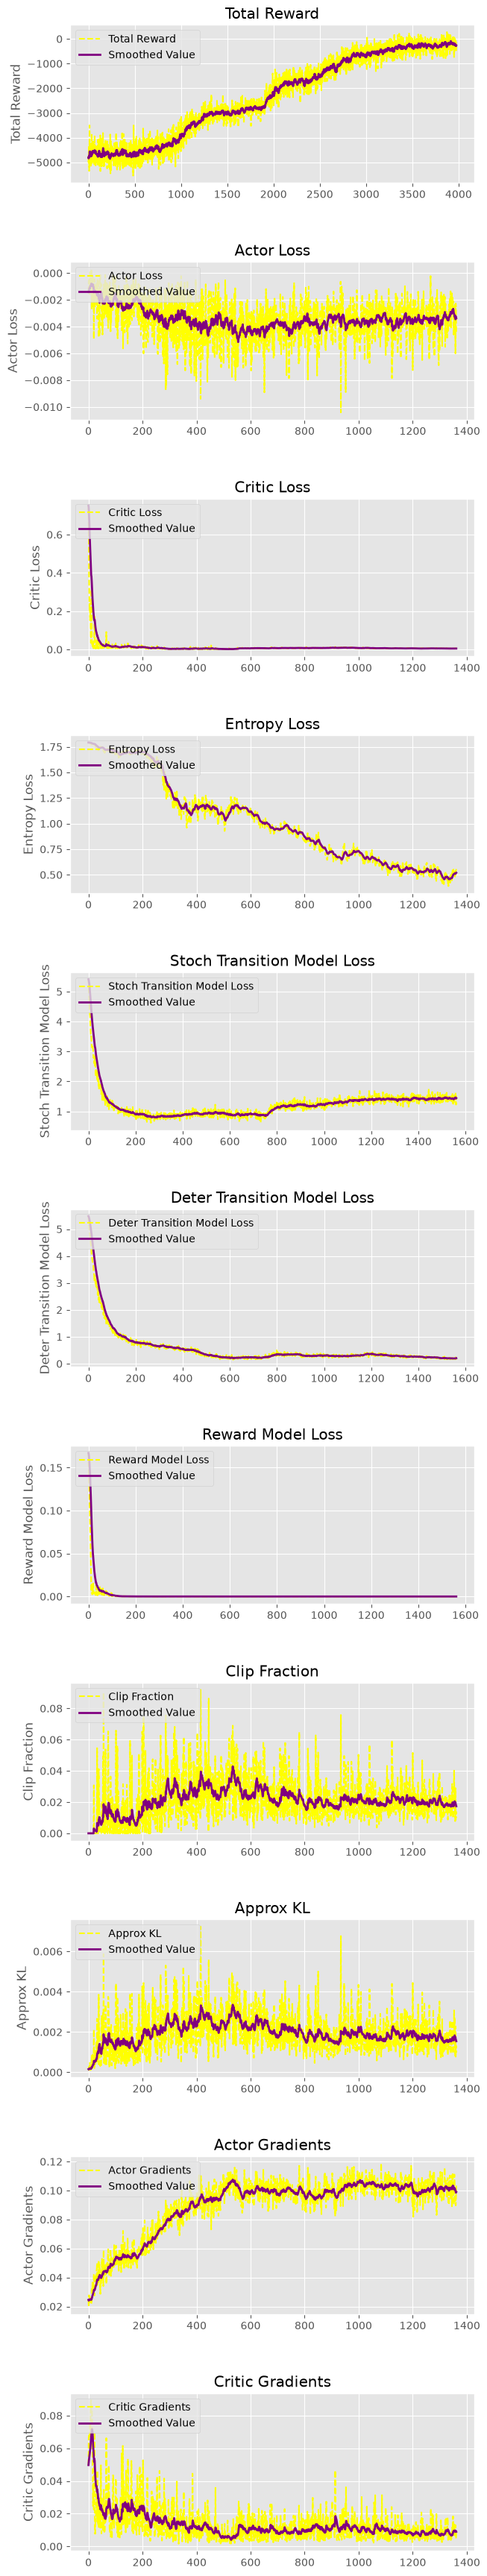

100%|██████████| 1562/1562 [38:08<00:00,  1.93s/it, episode_reward=-148, replay=2e+4]

100%|██████████| 1562/1562 [38:08<00:00,  1.47s/it, episode_reward=-148, replay=2e+4]

Training completed. Checkpoints saved to /tmp/claude-0/-home-claude/fc0c4b37-85ef-561a-9de9-03ce7effdc4a/scratchpad/a2-run/CSXX46A2-Student


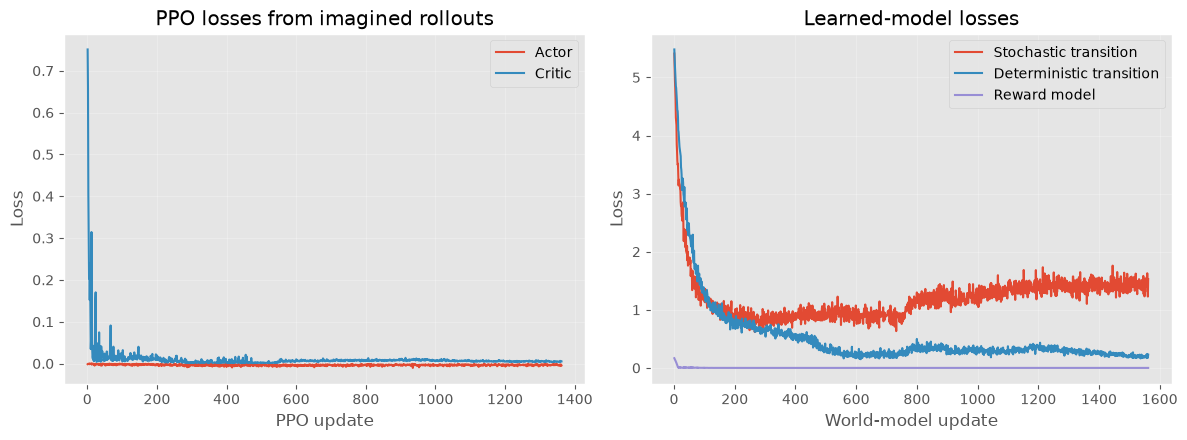

In [20]:
def episode_returns_from_vector_info(info):
    episode_returns = []
    if "episode" in info:
        mask = np.asarray(info.get("_episode", np.ones(NUM_ENVS, dtype=bool)))
        returns = np.asarray(info["episode"]["r"])
        episode_returns.extend(returns[mask].astype(float).tolist())
    elif "final_info" in info:
        for final_info in info["final_info"]:
            if final_info and "episode" in final_info:
                episode_returns.append(float(final_info["episode"]["r"]))
    return episode_returns


def mean_gradient_norm(parameters):
    norms = [parameter.grad.norm() for parameter in parameters if parameter.grad is not None]
    if not norms:
        return 0.0
    return torch.stack(norms).mean().item()


def plot_live_training_dashboard(history):
    """Show real returns and every training diagnostic in one dashboard."""
    diagnostic_history = {
        "Total Reward": history["Total Reward"],
        "Actor Loss": history["Actor Loss"],
        "Critic Loss": history["Critic Loss"],
        "Entropy Loss": history["Entropy"],
        "Stoch Transition Model Loss": history["Stochastic Transition Loss"],
        "Deter Transition Model Loss": history["Deterministic Transition Loss"],
        "Reward Model Loss": history["Reward Model Loss"],
        "Clip Fraction": history["Clip Fraction"],
        "Approx KL": history["Approx KL"],
        "Actor Gradients": history["Actor Gradients"],
        "Critic Gradients": history["Critic Gradients"],
    }
    live_plot(diagnostic_history)


def plot_training_diagnostics(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for key, label in (("Actor Loss", "Actor"), ("Critic Loss", "Critic")):
        if history[key]:
            axes[0].plot(np.arange(1, len(history[key]) + 1), history[key], label=label)
    axes[0].set_title("PPO losses from imagined rollouts")
    axes[0].set_xlabel("PPO update")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.25)
    if axes[0].lines:
        axes[0].legend()

    for key, label in (
        ("Stochastic Transition Loss", "Stochastic transition"),
        ("Deterministic Transition Loss", "Deterministic transition"),
        ("Reward Model Loss", "Reward model"),
    ):
        if history[key]:
            axes[1].plot(np.arange(1, len(history[key]) + 1), history[key], label=label)
    axes[1].set_title("Learned-model losses")
    axes[1].set_xlabel("World-model update")
    axes[1].set_ylabel("Loss")
    axes[1].grid(alpha=0.25)
    if axes[1].lines:
        axes[1].legend()
    fig.tight_layout()
    plt.show()


def train_model_based_ppo():
    history = {
        "Total Reward": [],
        "Actor Loss": [],
        "Critic Loss": [],
        "Entropy": [],
        "Stochastic Transition Loss": [],
        "Deterministic Transition Loss": [],
        "Reward Model Loss": [],
        "Clip Fraction": [],
        "Approx KL": [],
        "Actor Gradients": [],
        "Critic Gradients": [],
    }
    replay_buffer = deque(maxlen=REPLAY_BUFFER_SIZE)
    progress_bar = tqdm.tqdm(range(1, NUM_ITERATIONS + 1))
    first_return_plot_shown = False

    initial_observation, _ = envs.reset(seed=SEED)
    real_observation = torch.as_tensor(
        initial_observation, dtype=torch.float32, device=device
    )
    needs_autoreset = np.zeros(NUM_ENVS, dtype=bool)

    for iteration in progress_bar:
        for _ in range(ROLLOUT_STEPS):
            if iteration <= PRETRAIN_ITERATIONS:
                real_action = torch.as_tensor(
                    envs.action_space.sample(), dtype=torch.long, device=device
                )
            else:
                with torch.no_grad():
                    real_action, _ = agent.get_action(real_observation)

            next_observation_np, reward_np, terminated, truncated, info = envs.step(
                real_action.detach().cpu().numpy()
            )
            done_np = np.logical_or(terminated, truncated)
            valid_transition = np.logical_not(needs_autoreset)
            needs_autoreset = done_np.copy()

            transition_next_observation = torch.as_tensor(
                next_observation_np, dtype=torch.float32, device=device
            )
            normalized_reward = torch.as_tensor(
                normalize_reward(reward_np), dtype=torch.float32, device=device
            )
            done = torch.as_tensor(done_np, dtype=torch.float32, device=device)
            history["Total Reward"].extend(episode_returns_from_vector_info(info))

            ### ------------- TASK MB3 ------------- ###
            ### ----- YOUR CODES START HERE ------ ###
            for env_index in range(NUM_ENVS):
                if valid_transition[env_index]:
                    add_to_replay_buffer(
                        replay_buffer,
                        real_observation[env_index],
                        real_action[env_index],
                        normalized_reward[env_index],
                        transition_next_observation[env_index],
                        done[env_index],
                    )
            ### ------ YOUR CODES END HERE ------- ###

            real_observation = transition_next_observation

        ### ------------- TASK MB4 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        train_world_model = len(replay_buffer) >= MODEL_BATCH_SIZE
        ### ------ YOUR CODES END HERE ------- ###

        if train_world_model:
            stochastic_total = 0.0
            deterministic_total = 0.0
            reward_total = 0.0
            for _ in range(MODEL_TRAINING_NUM_EPOCHS):
                batch = sample_batch(replay_buffer, MODEL_BATCH_SIZE)
                total_loss, stochastic_loss, deterministic_loss, reward_loss = (
                    compute_model_losses(transition_model, reward_model, batch)
                )
                model_optimizer.zero_grad()
                total_loss.backward()
                nn.utils.clip_grad_norm_(transition_model.parameters(), 0.5)
                nn.utils.clip_grad_norm_(reward_model.parameters(), 0.5)
                model_optimizer.step()
                stochastic_total += stochastic_loss.item()
                deterministic_total += deterministic_loss.item()
                reward_total += reward_loss.item()

            history["Stochastic Transition Loss"].append(
                stochastic_total / MODEL_TRAINING_NUM_EPOCHS
            )
            history["Deterministic Transition Loss"].append(
                deterministic_total / MODEL_TRAINING_NUM_EPOCHS
            )
            history["Reward Model Loss"].append(
                reward_total / MODEL_TRAINING_NUM_EPOCHS
            )

        ### ------------- TASK MB6 ------------- ###
        ### ----- YOUR CODES START HERE ------ ###
        train_agent = iteration > PRETRAIN_ITERATIONS
        ### ------ YOUR CODES END HERE ------- ###

        if train_agent:
            repeat_factor = MODEL_NUM_ENVS // NUM_ENVS
            model_observation = real_observation.repeat(repeat_factor, 1)
            model_done = torch.zeros(MODEL_NUM_ENVS, device=device)

            with torch.no_grad():
                for step in range(MODEL_ROLLOUT_STEPS):
                    observation_rollout[step] = model_observation
                    done_rollout[step] = model_done
                    model_action, model_logprob = agent.get_action(model_observation)
                    model_value = agent.get_value(model_observation).squeeze(-1)

                    action_rollout[step] = model_action
                    logprob_rollout[step] = model_logprob
                    value_rollout[step] = model_value

                    model_outputs = transition_model(model_observation, model_action)
                    model_next_observation = construct_predicted_next_state(model_outputs)
                    model_reward = torch.sigmoid(
                        reward_model(model_observation)
                    ).squeeze(-1)
                    # The RDDL episode ends by a time-limit truncation, but time is
                    # not part of the learned state. Imagined rollouts therefore use
                    # a fixed horizon and no learned terminal-state condition.
                    model_done = torch.zeros(MODEL_NUM_ENVS, device=device)
                    reward_rollout[step] = model_reward
                    model_observation = model_next_observation

                last_value = agent.get_value(model_observation).squeeze(-1)
                advantages, returns = compute_gae(
                    reward_rollout,
                    value_rollout,
                    done_rollout,
                    last_value,
                    model_done,
                )

            flat_observations = observation_rollout.reshape(-1, OBS_SHAPE)
            flat_actions = action_rollout.reshape(-1)
            flat_logprobs = logprob_rollout.reshape(-1)
            flat_advantages = advantages.reshape(-1)
            flat_returns = returns.reshape(-1)
            flat_values = value_rollout.reshape(-1)

            indices = np.arange(BATCH_SIZE)
            actor_loss_total = 0.0
            critic_loss_total = 0.0
            entropy_total = 0.0
            clip_fraction_total = 0.0
            approx_kl_total = 0.0
            actor_gradients_total = 0.0
            critic_gradients_total = 0.0
            update_count = 0

            for _ in range(NUM_EPOCHS):
                np.random.shuffle(indices)
                for start in range(0, BATCH_SIZE, MINI_BATCH_SIZE):
                    mini_indices = indices[start : start + MINI_BATCH_SIZE]
                    mini_advantages = flat_advantages[mini_indices]
                    mini_advantages = (
                        mini_advantages - mini_advantages.mean()
                    ) / (mini_advantages.std() + 1e-8)

                    new_logprobs = agent.get_logprob(
                        flat_observations[mini_indices], flat_actions[mini_indices]
                    )
                    new_values = agent.get_value(
                        flat_observations[mini_indices]
                    ).squeeze(-1)
                    entropy = agent.get_entropy(flat_observations[mini_indices])

                    ratio = get_ratio(new_logprobs, flat_logprobs[mini_indices])
                    with torch.no_grad():
                        logratio = new_logprobs - flat_logprobs[mini_indices]
                        clip_fraction_total += (
                            ((ratio - 1.0).abs() > CLIP_COEF).float().mean().item()
                        )
                        approx_kl_total += ((ratio - 1.0) - logratio).mean().item()
                    policy_objective = get_policy_objective(mini_advantages, ratio)
                    critic_loss = get_value_loss(
                        new_values,
                        flat_values[mini_indices],
                        flat_returns[mini_indices],
                    )
                    entropy_objective = entropy.mean()
                    agent_loss = get_total_loss(
                        policy_objective, critic_loss, entropy_objective
                    )

                    agent_optimizer.zero_grad()
                    agent_loss.backward()
                    nn.utils.clip_grad_norm_(agent.parameters(), 0.5)
                    actor_gradients_total += mean_gradient_norm(
                        agent.actor.parameters()
                    )
                    critic_gradients_total += mean_gradient_norm(
                        agent.critic.parameters()
                    )
                    agent_optimizer.step()

                    actor_loss_total += (-policy_objective).item()
                    critic_loss_total += critic_loss.item()
                    entropy_total += entropy_objective.item()
                    update_count += 1

            history["Actor Loss"].append(actor_loss_total / update_count)
            history["Critic Loss"].append(critic_loss_total / update_count)
            history["Entropy"].append(entropy_total / update_count)
            history["Clip Fraction"].append(clip_fraction_total / update_count)
            history["Approx KL"].append(approx_kl_total / update_count)
            history["Actor Gradients"].append(
                actor_gradients_total / update_count
            )
            history["Critic Gradients"].append(
                critic_gradients_total / update_count
            )

        latest_reward = (
            history["Total Reward"][-1] if history["Total Reward"] else float("nan")
        )
        progress_bar.set_postfix(
            replay=len(replay_buffer), episode_reward=latest_reward
        )
        should_plot_dashboard = bool(history["Total Reward"]) and (
            not first_return_plot_shown
            or (PLOT_EVERY and iteration % PLOT_EVERY == 0)
            or iteration == NUM_ITERATIONS
        )
        if should_plot_dashboard:
            plot_live_training_dashboard(history)
            first_return_plot_shown = True

    torch.save(agent.state_dict(), ASSIGNMENT_DIR / "model_based_agent.pth")
    torch.save(transition_model.state_dict(), ASSIGNMENT_DIR / "transition_model.pth")
    torch.save(reward_model.state_dict(), ASSIGNMENT_DIR / "reward_model.pth")
    print(f"Training completed. Checkpoints saved to {ASSIGNMENT_DIR}")
    return history


training_history = train_model_based_ppo()
plot_training_diagnostics(training_history)


## Evaluation

Load the three modern checkpoints, run the learned policy for several real episodes, and collect the resulting transitions. The same replay data are then used to report a one-step transition-model mean-squared error.

**Evaluation Task.** Complete the marked interaction loop. Remember that an episode ends when either `terminated` or `truncated` is true.

The evaluation cell plots each real-environment episode return and their mean. These returns are separate from the imagined rollouts used for PPO updates.


/tmp/claude-0/-home-claude/fc0c4b37-85ef-561a-9de9-03ce7effdc4a/scratchpad/a2venv/lib/python3.13/site-packages/pyRDDLGym/core/debug/exception.py:28: UserWarning: State invariant 1 does not have a structure of <action or state fluent> <op> <rhs>, where <op> is one of {<=, <, >=, >} and <rhs> is a deterministic function of non-fluents only, and will be ignored.
>> ( sum_{?f: floor} [ elevator-at-floor(?e, ?f) ] ) == 1
  warnings.warn(message)


  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:00<00:04,  1.98it/s]

 20%|██        | 2/10 [00:00<00:03,  2.44it/s]

 30%|███       | 3/10 [00:01<00:02,  2.47it/s]

...

 80%|████████  | 8/10 [00:03<00:00,  2.69it/s]

 90%|█████████ | 9/10 [00:03<00:00,  2.37it/s]

100%|██████████| 10/10 [00:04<00:00,  2.19it/s]

100%|██████████| 10/10 [00:04<00:00,  2.41it/s]

Mean evaluation return: -264.60


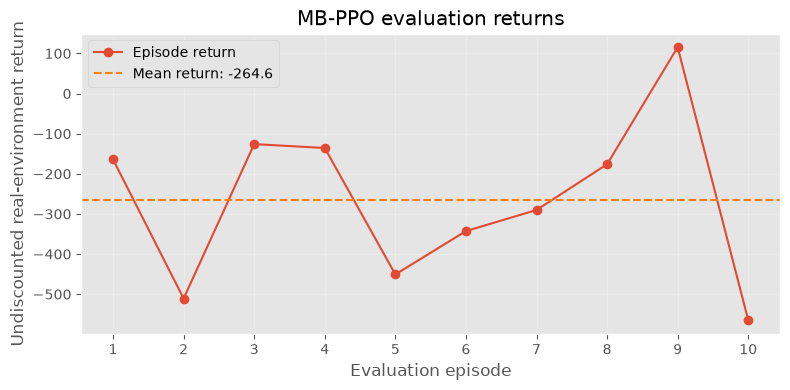

Mean one-step transition MSE: 0.072175


In [21]:
evaluation_agent = Agent(OBS_SHAPE, ACT_SHAPE, HIDDEN_SIZE).to(device)
evaluation_transition_model = TransitionModel(
    OBS_SHAPE, ACT_SHAPE, HIDDEN_SIZE
).to(device)
evaluation_reward_model = RewardModel(OBS_SHAPE, HIDDEN_SIZE).to(device)

evaluation_agent.load_state_dict(
    torch.load(ASSIGNMENT_DIR / "model_based_agent.pth", map_location=device, weights_only=True)
)
evaluation_transition_model.load_state_dict(
    torch.load(
        ASSIGNMENT_DIR / "transition_model.pth",
        map_location=device,
        weights_only=True,
    )
)
evaluation_reward_model.load_state_dict(
    torch.load(
        ASSIGNMENT_DIR / "reward_model.pth",
        map_location=device,
        weights_only=True,
    )
)
evaluation_agent.eval()
evaluation_transition_model.eval()
evaluation_reward_model.eval()

evaluation_env = create_elevator_env(record_statistics=False)
evaluation_replay = deque(maxlen=REPLAY_BUFFER_SIZE)
episode_returns = []
NUM_EVALUATION_EPISODES = 10

for episode in tqdm.tqdm(range(NUM_EVALUATION_EPISODES)):
    ### ------------- EVALUATION TASK ------------- ###
    ### ----- YOUR CODES START HERE ------ ###
    state, _ = evaluation_env.reset()
    episode_return = 0.0
    while True:
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)
        with torch.no_grad():
            action, _ = evaluation_agent.get_action(state_tensor)
        action_index = int(action.item())
        next_state, reward, terminated, truncated, _ = evaluation_env.step(action_index)
        done = bool(terminated or truncated)
        episode_return += float(reward)
        add_to_replay_buffer(
            evaluation_replay,
            state,
            action_index,
            normalize_reward(reward),
            next_state,
            float(done),
        )
        state = next_state
        if done:
            break
    episode_returns.append(episode_return)
    ### ------ YOUR CODES END HERE ------- ###

evaluation_env.close()
print(f"Mean evaluation return: {np.mean(episode_returns):.2f}")

if episode_returns:
    fig, ax = plt.subplots(figsize=(8, 4))
    episode_numbers = np.arange(1, len(episode_returns) + 1)
    ax.plot(episode_numbers, episode_returns, marker="o", label="Episode return")
    ax.axhline(
        np.mean(episode_returns), color="tab:orange", linestyle="--",
        label=f"Mean return: {np.mean(episode_returns):.1f}"
    )
    ax.set_xticks(episode_numbers)
    ax.set_xlabel("Evaluation episode")
    ax.set_ylabel("Undiscounted real-environment return")
    ax.set_title("MB-PPO evaluation returns")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()

transition_errors = []
number_of_batches = min(20, len(evaluation_replay) // MODEL_BATCH_SIZE)
with torch.no_grad():
    for _ in range(number_of_batches):
        batch = sample_batch(evaluation_replay, MODEL_BATCH_SIZE)
        states, actions, _, next_states, _ = batch
        predicted_next_states = construct_predicted_next_state(
            evaluation_transition_model(states, actions)
        )
        transition_errors.append(
            F.mse_loss(predicted_next_states, next_states).item()
        )

if transition_errors:
    print(f"Mean one-step transition MSE: {np.mean(transition_errors):.6f}")
else:
    print("Not enough evaluation transitions to compute model error.")


## Submission

Submit one `groupXX_assignment2.zip` for your team (replace `XX` with your Canvas group number). Put the completed `Model-BasedRL-Template.ipynb` with its executed training and evaluation graphs, the completed `Model-FreeRL-Template.ipynb` with its executed graphs, and these four checkpoint files directly at the ZIP root:

- `model_free_agent.pth`
- `model_based_agent.pth`
- `transition_model.pth`
- `reward_model.pth`

Do not submit the pre-migration checkpoints supplied with the legacy code: the current assignment uses the modern RDDL action ordering and an 11-class passenger-count head.
